# KO6 — Subagging-Ensemble LDA: Healthy vs PDAC

## Overview

Classifies **Healthy** (1000 Genomes Project, n=3,202) versus **PDAC** (TCGA-PAAD, n=167, TMB ≤ 500) using a subagging ensemble of Linear Discriminant Analysis (LDA) models over 9 literature-selected KoCoFX pathway features. Three feature representations are evaluated:

1. **Binary** — pathway mutation presence (1 if any mutated gene overlaps gene set, else 0)
2. **AM Max** — per-pathway maximum AlphaMissense pathogenicity score
3. **Pathogenic Binary** — binary presence of pathogenic mutations (AM ≥ 0.564)

Classification performance is estimated from out-of-fold (OOF) scores averaged across 100 bootstrap draws × 5-fold CV (500 fits per experiment). An apparent (train=test) fit provides an upper-bound reference per experiment. A single comparison section at the end consolidates all metrics and figures.

> **Note on metrics:** With 5% PDAC prevalence, **AUPRC is the primary metric**. AUROC can appear artificially high under large class imbalance because the false positive rate denominator (TN) is enormous; AUPRC directly evaluates precision on the minority class.

---

## KoCoFX-HvP Pathways

| # | Pathway | Level |
|---|---------|-------|
| 1 | REACTOME_Diseases of signal transduction by growth factor receptors and second messengers | L2 |
| 2 | REACTOME_Transcriptional regulation by RUNX3 | L4 |
| 3 | REACTOME_Cytokine Signaling in Immune system | L2 |
| 4 | REACTOME_Signaling by Receptor Tyrosine Kinases | L2 |
| 5 | REACTOME_Post-translational protein modification | L2 |
| 6 | REACTOME_Intracellular signaling by second messengers | L2 |
| 7 | REACTOME_Innate Immune System | L2 |
| 8 | REACTOME_Oncogenic MAPK signaling | L3 |
| 9 | HALLMARK_Fatty Acid Metabolism | — |

## Data

### Inputs

| File | Contents |
|------|----------|
| `merged_tcga_1000G.parquet` | Long-format somatic mutations: `source`, `sample_id`, `gene_name`, `am_pathogenicity` |
| `reactome_hierarchy/ReactomePathways.txt` | Reactome pathway ID → name → species |
| `reactome_hierarchy/ReactomePathwaysRelation.txt` | Reactome parent–child DAG edges |
| `reactome_hierarchy/ReactomePathways.gmt` | Reactome pathway ID → gene set |
| `healthy_downsampled_bootstrap.parquet` | 100 bootstrap draws × 3,202 individuals: `sample_id`, `gene_name`, `am_pathogenicity`, `bootstrap_id` |

### Processing

1. TCGA-PAAD patients with TMB > 500 are excluded.
2. Pathway gene sets are assembled from Hallmark (50) and Reactome L2–L4 (1,612); total 1,662.
3. Feature matrices are built per patient for the 9 KoCoFX-HvP pathways.
4. The label vector `y` (3,369 entries) and 10-fold stratified splits are fixed once (seed 42) and reused across all 1,000 draws.
5. Per draw: all 3,202 healthy mutation profiles from `bootstrap_id == b` are used without subsampling.
6. Results are written to `results/HvP_V2/`.

### Outputs

| File | Description |
|------|-------------|
| `LDA_KoCoFX_HvP_binary_cache.npz` | Subagging CV cache — binary |
| `LDA_KoCoFX_HvP_am_cache.npz` | Subagging CV cache — AM max |
| `LDA_KoCoFX_HvP_pathogenic_cache.npz` | Subagging CV cache — pathogenic binary |
| `LDA_KoCoFX_HvP_binary_apparent_cache.npz` | Apparent fit cache — binary |
| `LDA_KoCoFX_HvP_am_apparent_cache.npz` | Apparent fit cache — AM max |
| `LDA_KoCoFX_HvP_pathogenic_apparent_cache.npz` | Apparent fit cache — pathogenic binary |
| `LDA_KoCoFX_HvP_V2_results.txt` | Full metrics and coefficient table |
| `LDA_KoCoFX_HvP_V2_*.png` | All figures |


## Method

**Classifier:** `LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')` (Ledoit-Wolf regularised LDA). `StandardScaler` is fitted on the training fold only (no data leakage).

**Subagging design:** 100 bootstrap draws of healthy mutation profiles. All 3,202 healthy individuals are used per draw. The label vector `y` and 5-fold stratified splits are generated once from `y` (seed 42) and reused identically for every draw.

**Feature representations:**
- **Binary** — `build_koco_matrix`: 1.0 if any mutated gene overlaps a pathway gene set, else 0.0
- **AM Max** — `build_koco_am_matrix`: maximum `am_pathogenicity` over all overlapping mutations; 0.0 if none
- **Pathogenic Binary** — `build_koco_pathogenic_matrix`: 1.0 if any mutation with `am_pathogenicity ≥ 0.564` overlaps a pathway gene set, else 0.0

**OOF aggregation:** For each draw, out-of-fold scores are collected from all 10 folds. The final decision score per sample is the mean across 1,000 draws. Threshold-dependent metrics are computed at the F1-optimal threshold on these averaged scores.

**Apparent fit:** For each draw, LDA is fitted on all 3,369 samples and scored on the same samples (resubstitution). The headline apparent AUROC is the mean of per-draw apparent AUROCs — guaranteed ≥ mean of per-draw OOF AUROCs by construction per draw. The gap measures the generalization penalty.

**Stability:** Per-draw AUROC and AUPRC standard deviations quantify ensemble stability. Reported as `mean ± std` (std over 1,000 draws).

## Contents

| # | Section | Description |
|---|---------|-------------|
| 1 | Setup | Imports, constants, cache paths, feature-matrix helpers |
| 2 | PDAC Metadata | Load TCGA-PAAD, exclude hypermutator (TMB > 500) |
| 3 | Pathway Gene Sets | Reactome L2–L4 + Hallmark; verify 9 KoCoFX pathways |
| 4 | Feature Matrices | Build X_pdac_binary, X_pdac_am, X_pdac_pathogenic |
| 5 | Bootstrap Draws & Fixed Folds | Load bootstrap parquet; define fixed 10-fold splits |
| 6 | Experiment 1 — Binary | Pathway prevalence, subagging CV, apparent fit, per-experiment metrics |
| 7 | Experiment 2 — AM Max | Per-pathway AM stats, subagging CV, apparent fit, per-experiment metrics |
| 8 | Experiment 3 — Pathogenic Binary | Pathogenic prevalence, subagging CV, apparent fit, per-experiment metrics |
| 9 | Comparison | Unified metrics table; ROC/PR overlay; confusion matrix, coef bar, and violin grids |
| 10 | Results File | Write text summary to `LDA_KoCoFX_HvP_V2_results.txt` |

## 1. Setup

In [2]:
from collections import defaultdict, deque
import json
import re
import warnings
from pathlib import Path

from IPython.display import display
import gseapy as gp
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)

AM_PATH_MIN = 0.564   # AlphaMissense pathogenic threshold (inclusive)

KOCOFX_HVP_PATHWAYS = [
    'REACTOME_Diseases of signal transduction by growth factor receptors and second messengers',
    'REACTOME_Transcriptional regulation by RUNX3',
    'REACTOME_Cytokine Signaling in Immune system',
    'REACTOME_Signaling by Receptor Tyrosine Kinases',
    'REACTOME_Post-translational protein modification',
    'REACTOME_Intracellular signaling by second messengers',
    'REACTOME_Innate Immune System',
    'REACTOME_Oncogenic MAPK signaling',
    'HALLMARK_Fatty Acid Metabolism',
]

N_DRAWS            = 100
N_CV_SPLITS        = 5
RANDOM_SEED        = 42
MAX_REACTOME_LEVEL = 3
MIN_REACTOME_LEVEL = 1

# DATA_DIR          = Path('C:/Users/daane/Desktop/DATA')
DATA_DIR          = Path('C:/2604_BRP/Data')
REPO_DATA         = Path('../3_Data')   # merged + healthy bootstrap parquets shipped with the repo
PARQUET           = REPO_DATA / 'merged_tcga_1000G.parquet'
REACTOME_DIR      = DATA_DIR / 'reactome_hierarchy'
BOOTSTRAP_PARQUET = REPO_DATA / 'healthy_downsampled_bootstrap.parquet'
RESULTS_DIR       = DATA_DIR / 'results' / 'HvP_V2'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CACHE_BINARY     = RESULTS_DIR / 'LDA_KoCoFX_HvP_binary_cache.npz'
CACHE_AM         = RESULTS_DIR / 'LDA_KoCoFX_HvP_am_cache.npz'
CACHE_PATHOGENIC = RESULTS_DIR / 'LDA_KoCoFX_HvP_pathogenic_cache.npz'
CACHE_BINARY_AP  = RESULTS_DIR / 'LDA_KoCoFX_HvP_binary_apparent_cache.npz'
CACHE_AM_AP      = RESULTS_DIR / 'LDA_KoCoFX_HvP_am_apparent_cache.npz'
CACHE_PATH_AP    = RESULTS_DIR / 'LDA_KoCoFX_HvP_pathogenic_apparent_cache.npz'

WONG = {
    'orange':    '#E69F00',
    'sky_blue':  '#56B4E9',
    'green':     '#009E73',
    'blue':      '#0072B2',
    'vermilion': '#D55E00',
    'pink':      '#CC79A7',
}


def build_koco_matrix(sample_ids, sample_gene_sets, pathways, pw_sets):
    # Binary: 1.0 if any mutated gene overlaps pathway gene set, else 0.0
    gene_to_pw = defaultdict(list)
    for j, pw in enumerate(pathways):
        for g in pw_sets[pw]:
            gene_to_pw[g].append(j)
    X = np.zeros((len(sample_ids), len(pathways)), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for g in sample_gene_sets.get(sid, set()):
            for j in gene_to_pw.get(g, []):
                X[i, j] = 1.0
    return X


def build_koco_am_matrix(sample_ids, sample_mutations, pathways, pw_sets):
    # AM Max: max(am_pathogenicity) over mutations overlapping pathway; 0.0 if none
    gene_to_pw = defaultdict(list)
    for j, pw in enumerate(pathways):
        for g in pw_sets[pw]:
            gene_to_pw[g].append(j)
    X = np.zeros((len(sample_ids), len(pathways)), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for gene, score in sample_mutations.get(sid, []):
            for j in gene_to_pw.get(gene, []):
                if score > X[i, j]:
                    X[i, j] = score
    return X


def build_koco_pathogenic_matrix(sample_ids, sample_mutations, pathways, pw_sets, threshold=AM_PATH_MIN):
    # Pathogenic binary: 1.0 if any mutation with am_pathogenicity >= threshold overlaps pathway
    gene_to_pw = defaultdict(list)
    for j, pw in enumerate(pathways):
        for g in pw_sets[pw]:
            gene_to_pw[g].append(j)
    X = np.zeros((len(sample_ids), len(pathways)), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for gene, score in sample_mutations.get(sid, []):
            if score >= threshold:
                for j in gene_to_pw.get(gene, []):
                    X[i, j] = 1.0
    return X


print(f'Results dir       : {RESULTS_DIR}')
print(f'Parquet exists    : {PARQUET.exists()}')
print(f'Bootstrap parquet : {BOOTSTRAP_PARQUET.exists()}')
print(f'Draws             : {N_DRAWS} x {N_CV_SPLITS}-fold CV = {N_DRAWS * N_CV_SPLITS:,} fits per experiment')


KeyError: '__reduce_cython__'

## 2. PDAC Metadata

In [2]:
tmb_df = (
    pl.read_parquet(PARQUET, columns=['source', 'sample_id'])
    .filter(pl.col('source') == 'TCGA')
    .group_by('sample_id')
    .agg(pl.len().alias('tmb'))
)
hypermutator_ids = set(
    tmb_df.filter(pl.col('tmb') > 500)['sample_id'].to_list()
)

pdac_ids = sorted(
    pl.read_parquet(PARQUET, columns=['source', 'sample_id'])
    .filter(
        (pl.col('source') == 'TCGA') &
        ~pl.col('sample_id').is_in(hypermutator_ids)
    )
    .unique('sample_id')
    ['sample_id']
    .to_list()
)
N_PDAC = len(pdac_ids)

print(f'Hypermutators excluded (TMB > 500) : {sorted(hypermutator_ids)}')
print(f'PDAC patients retained (n)         : {N_PDAC}')


Hypermutators excluded (TMB > 500) : ['TCGA-IB-7651']
PDAC patients retained (n)         : 167


## 3. Pathway Gene Sets

In [3]:
pw_txt  = (REACTOME_DIR / 'ReactomePathways.txt').read_text(encoding='utf-8')
rel_txt = (REACTOME_DIR / 'ReactomePathwaysRelation.txt').read_text(encoding='utf-8')
gmt_txt = (REACTOME_DIR / 'ReactomePathways.gmt').read_text(encoding='utf-8')

human_id_to_name = {}
for line in pw_txt.strip().splitlines():
    parts = line.split('\t')
    if len(parts) >= 3 and parts[2].strip() == 'Homo sapiens':
        human_id_to_name[parts[0].strip()] = parts[1].strip()
human_ids = set(human_id_to_name)

parent_to_children = defaultdict(set)
child_to_parents   = defaultdict(set)
for line in rel_txt.strip().splitlines():
    parts = line.strip().split('\t')
    if len(parts) < 2:
        continue
    parent, child = parts[0], parts[1]
    if parent in human_ids and child in human_ids:
        parent_to_children[parent].add(child)
        child_to_parents[child].add(parent)

all_in_dag = set(parent_to_children) | set(child_to_parents)
roots      = {pid for pid in all_in_dag if pid not in child_to_parents}
level_of   = {}
queue = deque()
for r in roots:
    level_of[r] = 0
    queue.append(r)
while queue:
    node = queue.popleft()
    for child in parent_to_children.get(node, set()):
        if child not in level_of:
            level_of[child] = level_of[node] + 1
            queue.append(child)

gmt_by_id  = {}
name_to_id = {}
for line in gmt_txt.strip().splitlines():
    parts = line.split('\t')
    if len(parts) < 3:
        continue
    name  = parts[0]
    url   = parts[1]
    genes = {g.strip() for g in parts[2:] if g.strip()}
    m = re.search(r'R-HSA-\d+', url)
    if not m:
        continue
    rid = m.group(0)
    gmt_by_id[rid]   = {'name': name, 'genes': genes}
    name_to_id[name] = rid

_raw_hallmark = gp.get_library('MSigDB_Hallmark_2020')
hallmark_sets = {k: set(v) for k, v in _raw_hallmark.items()}

reactome_selected = {}
for rid, info in gmt_by_id.items():
    if MIN_REACTOME_LEVEL <= level_of.get(rid, 99) <= MAX_REACTOME_LEVEL and info['genes']:
        reactome_selected[info['name']] = info['genes']

pw_sets = {}
for name, genes in hallmark_sets.items():
    pw_sets[f'HALLMARK_{name}'] = genes
for name, genes in reactome_selected.items():
    key = f'REACTOME_{name}'
    if key not in pw_sets:
        pw_sets[key] = genes


def pw_level_tag(pw_name):
    if not pw_name.startswith('REACTOME_'):
        return ''
    base = pw_name[len('REACTOME_'):]
    rid  = name_to_id.get(base)
    if rid is None:
        return ''
    lv = level_of.get(rid)
    return f'(L{lv + 1})' if lv is not None else ''


for lv in range(MIN_REACTOME_LEVEL, MAX_REACTOME_LEVEL + 1):
    n = sum(1 for rid in gmt_by_id if level_of.get(rid) == lv)
    print(f'Reactome-L{lv + 1}: {n} pathways')
print(f'Reactome L2-L4 with genes : {len(reactome_selected)}')
print(f'Hallmark pathways          : {len(hallmark_sets)}')
print(f'Total pw_sets              : {len(pw_sets)}')

for pw in KOCOFX_HVP_PATHWAYS:
    if pw not in pw_sets:
        raise KeyError(f'KoCoFX pathway not found in pw_sets: {pw!r}')
print('All 9 KoCoFX-HvP pathways present in pw_sets.')


Reactome-L2: 188 pathways
Reactome-L3: 504 pathways
Reactome-L4: 920 pathways
Reactome L2-L4 with genes : 1612
Hallmark pathways          : 50
Total pw_sets              : 1662
All 9 KoCoFX-HvP pathways present in pw_sets.


## 4. Feature Matrices

In [4]:
_parquet_cols = pl.scan_parquet(PARQUET).columns
if 'am_pathogenicity' not in _parquet_cols:
    raise KeyError(
        "Column 'am_pathogenicity' not found in PARQUET. "
        f"Fallback path: {DATA_DIR / 'tcga_paad_alphamissense.parquet'}"
    )

df_tcga = (
    pl.read_parquet(PARQUET, columns=['source', 'sample_id', 'gene_name', 'am_pathogenicity'])
    .filter(
        (pl.col('source') == 'TCGA') &
        pl.col('sample_id').is_in(pdac_ids)
    )
    .drop_nulls('gene_name')
)

# Binary feature — any mutated gene overlaps pathway
pdac_gene_sets = {}
for row in (
    df_tcga.unique(['sample_id', 'gene_name'])
    .group_by('sample_id')
    .agg(pl.col('gene_name'))
    .iter_rows(named=True)
):
    pdac_gene_sets[row['sample_id']] = set(row['gene_name'])

X_pdac_binary = build_koco_matrix(pdac_ids, pdac_gene_sets, KOCOFX_HVP_PATHWAYS, pw_sets)
assert X_pdac_binary.shape == (N_PDAC, len(KOCOFX_HVP_PATHWAYS))

# AM Max and Pathogenic Binary — require am_pathogenicity
df_tcga_am = df_tcga.drop_nulls('am_pathogenicity')
pdac_am_mutations = {}
for row in (
    df_tcga_am.group_by('sample_id')
    .agg([pl.col('gene_name'), pl.col('am_pathogenicity')])
    .iter_rows(named=True)
):
    pdac_am_mutations[row['sample_id']] = [
        (g, float(s))
        for g, s in zip(row['gene_name'], row['am_pathogenicity'])
        if s is not None
    ]

X_pdac_am = build_koco_am_matrix(pdac_ids, pdac_am_mutations, KOCOFX_HVP_PATHWAYS, pw_sets)
assert X_pdac_am.shape == (N_PDAC, len(KOCOFX_HVP_PATHWAYS))
assert float(X_pdac_am.min()) >= 0.0 and float(X_pdac_am.max()) <= 1.0

X_pdac_pathogenic = build_koco_pathogenic_matrix(pdac_ids, pdac_am_mutations, KOCOFX_HVP_PATHWAYS, pw_sets)
assert X_pdac_pathogenic.shape == (N_PDAC, len(KOCOFX_HVP_PATHWAYS))
assert (X_pdac_pathogenic <= X_pdac_binary).all(), 'Pathogenic matrix is not a subset of binary matrix'

print(f'X_pdac_binary     : {X_pdac_binary.shape}   dtype={X_pdac_binary.dtype}')
print(f'X_pdac_am         : {X_pdac_am.shape}   dtype={X_pdac_am.dtype}   range=[{float(X_pdac_am.min()):.4f}, {float(X_pdac_am.max()):.4f}]')
print(f'X_pdac_pathogenic : {X_pdac_pathogenic.shape}   dtype={X_pdac_pathogenic.dtype}')


X_pdac_binary     : (167, 9)   dtype=float32
X_pdac_am         : (167, 9)   dtype=float32   range=[0.0000, 1.0000]
X_pdac_pathogenic : (167, 9)   dtype=float32


C:\Users\daane\AppData\Local\Temp\ipykernel_47388\2049920885.py:1: PerformanceWarning: Determining the column names of a LazyFrame requires resolving its schema, which is a potentially expensive operation. Use `LazyFrame.collect_schema().names()` to get the column names without this warning.
  _parquet_cols = pl.scan_parquet(PARQUET).columns


## 5. Bootstrap Draws & Fixed Folds

In [5]:
print(f'Loading: {BOOTSTRAP_PARQUET}')
df_bootstrap = pl.read_parquet(BOOTSTRAP_PARQUET)
print(f'Loaded  : {df_bootstrap.shape[0]:,} rows x {df_bootstrap.shape[1]} cols')
print(f'Bootstraps  : {df_bootstrap["bootstrap_id"].n_unique()}')
print(f'Individuals : {df_bootstrap["sample_id"].n_unique():,}')
print(f'Columns     : {df_bootstrap.columns}')

N_HEALTHY = df_bootstrap['sample_id'].n_unique()
n_total   = N_HEALTHY + N_PDAC
y         = np.array([0] * N_HEALTHY + [1] * N_PDAC, dtype=np.int8)

skf    = StratifiedKFold(n_splits=N_CV_SPLITS, shuffle=True, random_state=RANDOM_SEED)
splits = list(skf.split(np.arange(n_total), y))

print(f'\nCohort: {N_HEALTHY:,} healthy + {N_PDAC} PDAC = {n_total} total')
print(f'Label vector y: shape={y.shape}, PDAC fraction={y.mean():.4f}')
print(f'Fixed {N_CV_SPLITS}-fold splits generated (seed={RANDOM_SEED}), reused across all {N_DRAWS} draws.')

pdac_prevalence = float((y == 1).mean())
print(f'PDAC prevalence : {pdac_prevalence:.4f}')

Loading: C:\Users\daane\Desktop\DATA\healthy_downsampled_bootstrap.parquet
Loaded  : 84,702,714 rows x 5 cols
Bootstraps  : 1000
Individuals : 3,202
Columns     : ['sample_id', 'gene_name', 'protein_variant', 'am_pathogenicity', 'bootstrap_id']

Cohort: 3,202 healthy + 167 PDAC = 3369 total
Label vector y: shape=(3369,), PDAC fraction=0.0496
Fixed 5-fold splits generated (seed=42), reused across all 100 draws.
PDAC prevalence : 0.0496


## 6. Experiment 1 — Binary

Each of the 9 pathways is represented as a binary indicator: 1 if any mutated gene overlaps the pathway gene set, 0 otherwise.

In [6]:
display(pl.DataFrame({
    'Pathway': [
        pw.replace('REACTOME_', '').replace('HALLMARK_', '') + ' ' + pw_level_tag(pw)
        for pw in KOCOFX_HVP_PATHWAYS
    ],
    'n_mutated':  [int(X_pdac_binary[:, i].sum()) for i in range(len(KOCOFX_HVP_PATHWAYS))],
    'prevalence': [f'{100 * X_pdac_binary[:, i].mean():.1f}%' for i in range(len(KOCOFX_HVP_PATHWAYS))],
}))


Pathway,n_mutated,prevalence
str,i64,str
"""Diseases of signal transductio…",140,"""83.8%"""
"""Transcriptional regulation by …",130,"""77.8%"""
"""Cytokine Signaling in Immune s…",136,"""81.4%"""
"""Signaling by Receptor Tyrosine…",141,"""84.4%"""
"""Post-translational protein mod…",138,"""82.6%"""
"""Intracellular signaling by sec…",98,"""58.7%"""
"""Innate Immune System (L2)""",141,"""84.4%"""
"""Oncogenic MAPK signaling (L3)""",114,"""68.3%"""
"""Fatty Acid Metabolism """,21,"""12.6%"""


In [7]:
if CACHE_BINARY.exists():
    _d = np.load(CACHE_BINARY, allow_pickle=False)
    oof_scores_bin = list(_d['oof_scores'])
    coefs_bin      = list(_d['coefs'])
    draw_aucs_bin  = list(_d['per_draw_aucs'])
    if 'per_draw_auprcs' in _d.files:
        draw_auprcs_bin = list(_d['per_draw_auprcs'])
    else:
        print('Computing per_draw_auprcs from stored OOF scores...')
        draw_auprcs_bin = [
            float(average_precision_score(y, _d['oof_scores'][b]))
            for b in range(len(oof_scores_bin))
        ]
    if 'fold_auprcs' in _d.files:
        fold_auprcs_bin = [list(row) for row in _d['fold_auprcs']]
    else:
        fold_auprcs_bin = []
    start_draw = len(oof_scores_bin)
    print(f'Resuming binary CV from draw {start_draw}/{N_DRAWS}')
else:
    oof_scores_bin, coefs_bin, draw_aucs_bin, draw_auprcs_bin, fold_auprcs_bin = [], [], [], [], []
    start_draw = 0
    print('Starting binary subagging CV')

for b in tqdm(range(start_draw, N_DRAWS), desc='Draws (binary)', initial=start_draw, total=N_DRAWS):
    df_b          = df_bootstrap.filter(pl.col('bootstrap_id') == b)
    healthy_ids_b = sorted(df_b['sample_id'].unique().to_list())

    healthy_gene_sets = {}
    for row in (
        df_b.drop_nulls('gene_name')
        .unique(['sample_id', 'gene_name'])
        .group_by('sample_id')
        .agg(pl.col('gene_name'))
        .iter_rows(named=True)
    ):
        healthy_gene_sets[row['sample_id']] = set(row['gene_name'])

    X_healthy_b = build_koco_matrix(healthy_ids_b, healthy_gene_sets, KOCOFX_HVP_PATHWAYS, pw_sets)
    X_b   = np.vstack([X_healthy_b, X_pdac_binary])
    oof_b       = np.zeros(n_total, dtype=np.float32)
    coefs_b       = []
    fold_auprcs_b = []

    for train_idx, test_idx in splits:
        sc  = StandardScaler().fit(X_b[train_idx])
        Xtr = sc.transform(X_b[train_idx])
        Xte = sc.transform(X_b[test_idx])
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
            lda.fit(Xtr, y[train_idx])
        oof_b[test_idx] = lda.decision_function(Xte)
        coefs_b.append(lda.coef_[0])
        fold_auprcs_b.append(float(average_precision_score(y[test_idx], oof_b[test_idx])))

    oof_scores_bin.append(oof_b)
    fold_auprcs_bin.append(fold_auprcs_b)
    coefs_bin.extend(coefs_b)
    draw_aucs_bin.append(float(roc_auc_score(y, oof_b)))
    draw_auprcs_bin.append(float(average_precision_score(y, oof_b)))

    np.savez(
        CACHE_BINARY,
        oof_scores      = np.array(oof_scores_bin, dtype=np.float32),
        coefs           = np.array(coefs_bin,       dtype=np.float32),
        per_draw_aucs   = np.array(draw_aucs_bin,   dtype=np.float64),
        per_draw_auprcs = np.array(draw_auprcs_bin, dtype=np.float64),
        fold_auprcs     = np.array(fold_auprcs_bin, dtype=np.float64),
    )

oof_scores_bin_arr  = np.array(oof_scores_bin,  dtype=np.float32)
coefs_bin_arr       = np.array(coefs_bin,        dtype=np.float32)
draw_aucs_bin_arr   = np.array(draw_aucs_bin,    dtype=np.float64)
draw_auprcs_bin_arr = np.array(draw_auprcs_bin,  dtype=np.float64)
fold_auprcs_bin_arr = np.array(fold_auprcs_bin,  dtype=np.float64)

assert oof_scores_bin_arr.shape == (N_DRAWS, n_total), f'Shape mismatch: {oof_scores_bin_arr.shape}'
assert not np.isnan(oof_scores_bin_arr).any(), 'NaN values in binary OOF scores'

# Resave if cache was complete but lacked per_draw_auprcs (backward compat)
if start_draw == N_DRAWS:
    np.savez(
        CACHE_BINARY,
        oof_scores      = oof_scores_bin_arr,
        coefs           = coefs_bin_arr,
        per_draw_aucs   = draw_aucs_bin_arr,
        per_draw_auprcs = draw_auprcs_bin_arr,
        fold_auprcs     = fold_auprcs_bin_arr,
    )

print(f'oof_scores_bin_arr  : {oof_scores_bin_arr.shape}')
print(f'coefs_bin_arr       : {coefs_bin_arr.shape}')
print(f'draw_auprcs_bin_arr : {draw_auprcs_bin_arr.shape}')


Starting binary subagging CV


Draws (binary):   0%|          | 0/100 [00:00<?, ?it/s]

oof_scores_bin_arr  : (100, 3369)
coefs_bin_arr       : (500, 9)
draw_auprcs_bin_arr : (100,)


In [8]:
if CACHE_BINARY_AP.exists():
    _d_ap = np.load(CACHE_BINARY_AP, allow_pickle=False)
    apparent_scores_bin = list(_d_ap['apparent_scores'])
    apparent_aucs_bin   = list(_d_ap['per_draw_apparent_aucs'])
    start_ap_bin        = len(apparent_scores_bin)
    print(f'Resuming apparent (binary) from draw {start_ap_bin}/{N_DRAWS}')
else:
    apparent_scores_bin, apparent_aucs_bin = [], []
    start_ap_bin = 0
    print('Starting apparent fit (binary)')

for b in tqdm(range(start_ap_bin, N_DRAWS), desc='Apparent (binary)', initial=start_ap_bin, total=N_DRAWS):
    df_b          = df_bootstrap.filter(pl.col('bootstrap_id') == b)
    healthy_ids_b = sorted(df_b['sample_id'].unique().to_list())

    healthy_gene_sets = {}
    for row in (
        df_b.drop_nulls('gene_name')
        .unique(['sample_id', 'gene_name'])
        .group_by('sample_id')
        .agg(pl.col('gene_name'))
        .iter_rows(named=True)
    ):
        healthy_gene_sets[row['sample_id']] = set(row['gene_name'])

    X_healthy_b = build_koco_matrix(healthy_ids_b, healthy_gene_sets, KOCOFX_HVP_PATHWAYS, pw_sets)
    X_b = np.vstack([X_healthy_b, X_pdac_binary])

    sc  = StandardScaler().fit(X_b)
    Xsc = sc.transform(X_b)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
        lda.fit(Xsc, y)
    ap_b = lda.decision_function(Xsc)

    apparent_scores_bin.append(ap_b.astype(np.float32))
    apparent_aucs_bin.append(float(roc_auc_score(y, ap_b)))

    np.savez(
        CACHE_BINARY_AP,
        apparent_scores        = np.array(apparent_scores_bin, dtype=np.float32),
        per_draw_apparent_aucs = np.array(apparent_aucs_bin,   dtype=np.float64),
    )

apparent_scores_bin_arr = np.array(apparent_scores_bin, dtype=np.float32)
apparent_aucs_bin_arr   = np.array(apparent_aucs_bin,   dtype=np.float64)
assert apparent_scores_bin_arr.shape == (N_DRAWS, n_total), f'Shape mismatch: {apparent_scores_bin_arr.shape}'
assert not np.isnan(apparent_scores_bin_arr).any(), 'NaN in apparent binary scores'
print(f'apparent_scores_bin_arr : {apparent_scores_bin_arr.shape}')


Starting apparent fit (binary)


Apparent (binary):   0%|          | 0/100 [00:00<?, ?it/s]

apparent_scores_bin_arr : (100, 3369)


In [9]:
mean_coef_bin = coefs_bin_arr.mean(axis=0)
std_coef_bin  = coefs_bin_arr.std(axis=0)

# AUROC / AUPRC (OOF) — Method B: per-draw mean ± std
auroc_bin          = float(draw_aucs_bin_arr.mean())
auprc_bin          = float(draw_auprcs_bin_arr.mean())
draw_auc_std_bin   = float(draw_aucs_bin_arr.std())
draw_auprc_std_bin = float(draw_auprcs_bin_arr.std())

# Apparent AUROC — already per-draw mean; add std
auroc_apparent_bin     = float(apparent_aucs_bin_arr.mean())
auroc_apparent_std_bin = float(apparent_aucs_bin_arr.std())

# Apparent AUPRC — compute per-draw (not cached)
draw_apparent_auprcs_bin_arr = np.array([
    average_precision_score(y, apparent_scores_bin_arr[b])
    for b in range(N_DRAWS)
])
auprc_apparent_bin     = float(draw_apparent_auprcs_bin_arr.mean())
auprc_apparent_std_bin = float(draw_apparent_auprcs_bin_arr.std())

# Per-draw CM stats — F1-optimal threshold per draw
_prec, _rec, _spec, _f1, _thresh = [], [], [], [], []
for b in range(N_DRAWS):
    prec_c, rec_c, thr_c = precision_recall_curve(y, oof_scores_bin_arr[b])
    f1_c = np.where(
        (prec_c[:-1] + rec_c[:-1]) > 0,
        2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]),
        0.0,
    )
    thr_b    = float(thr_c[np.argmax(f1_c)])
    y_pred_b = (oof_scores_bin_arr[b] >= thr_b).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, y_pred_b).ravel()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    s = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    _prec.append(p);  _rec.append(r);  _spec.append(s)
    _f1.append(2 * p * r / (p + r + 1e-12))
    _thresh.append(thr_b)

_f1_arr_bin = np.array(_f1)
_thresh_arr_bin = np.array(_thresh)

precision_bin       = float(np.mean(_prec));  precision_std_bin   = float(np.std(_prec))
recall_bin          = float(np.mean(_rec));   recall_std_bin      = float(np.std(_rec))
specificity_bin     = float(np.mean(_spec));  specificity_std_bin = float(np.std(_spec))
f1_bin              = float(np.mean(_f1));    f1_std_bin          = float(np.std(_f1))
threshold_bin       = float(np.mean(_thresh))

if draw_auc_std_bin >= 0.02:
    print(f'WARNING: per-draw AUC std = {draw_auc_std_bin:.4f} (> 0.02)')

display(pl.DataFrame({
    'Metric': [
        'AUROC (OOF)', 'AUPRC (OOF)',
        'AUROC (Apparent)', 'AUPRC (Apparent)',
        'Precision', 'Recall', 'Specificity', 'F1',
    ],
    'Value': [
        f'{auroc_bin:.4f} ± {draw_auc_std_bin:.4f}',
        f'{auprc_bin:.4f} ± {draw_auprc_std_bin:.4f}',
        f'{auroc_apparent_bin:.4f} ± {auroc_apparent_std_bin:.4f}',
        f'{auprc_apparent_bin:.4f} ± {auprc_apparent_std_bin:.4f}',
        f'{precision_bin:.4f} ± {precision_std_bin:.4f}',
        f'{recall_bin:.4f} ± {recall_std_bin:.4f}',
        f'{specificity_bin:.4f} ± {specificity_std_bin:.4f}',
        f'{f1_bin:.4f} ± {f1_std_bin:.4f}',
    ],
    'Note': [
        f'mean ± std over {N_DRAWS} draws', f'mean ± std over {N_DRAWS} draws',
        f'mean ± std over {N_DRAWS} draws', f'mean ± std over {N_DRAWS} draws',
        'per-draw F1-opt threshold', 'per-draw F1-opt threshold', 'per-draw F1-opt threshold',
        'per-draw F1-opt threshold',
    ],
}))


C:\Users\daane\AppData\Local\Temp\ipykernel_47388\1443339750.py:28: RuntimeWarning: invalid value encountered in divide
  2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]),
C:\Users\daane\AppData\Local\Temp\ipykernel_47388\1443339750.py:28: RuntimeWarning: invalid value encountered in divide
  2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]),
C:\Users\daane\AppData\Local\Temp\ipykernel_47388\1443339750.py:28: RuntimeWarning: invalid value encountered in divide
  2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]),
C:\Users\daane\AppData\Local\Temp\ipykernel_47388\1443339750.py:28: RuntimeWarning: invalid value encountered in divide
  2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]),
C:\Users\daane\AppData\Local\Temp\ipykernel_47388\1443339750.py:28: RuntimeWarning: invalid value encountered in divide
  2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]),
C:\Users\daane\AppData\Local\Temp\ipykernel_47388\1443339750.py:28: RuntimeWarning: invalid val

Metric,Value,Note
str,str,str
"""AUROC (OOF)""","""0.9237 ± 0.0031""","""mean ± std over 100 draws"""
"""AUPRC (OOF)""","""0.7427 ± 0.0186""","""mean ± std over 100 draws"""
"""AUROC (Apparent)""","""0.9304 ± 0.0023""","""mean ± std over 100 draws"""
"""AUPRC (Apparent)""","""0.7526 ± 0.0157""","""mean ± std over 100 draws"""
"""Precision""","""0.9331 ± 0.0223""","""per-draw F1-opt threshold"""
"""Recall""","""0.6537 ± 0.0024""","""per-draw F1-opt threshold"""
"""Specificity""","""0.9975 ± 0.0009""","""per-draw F1-opt threshold"""
"""F1""","""0.7687 ± 0.0079""","""per-draw F1-opt threshold"""


## 7. Experiment 2 — AM Max

Each pathway is represented by the maximum AlphaMissense pathogenicity score over all mutations whose gene overlaps the gene set; 0.0 if no overlap.

In [10]:
_rows = []
for i, pw in enumerate(KOCOFX_HVP_PATHWAYS):
    col     = X_pdac_am[:, i]
    nonzero = col[col > 0]
    _rows.append({
        'Pathway':     pw.replace('REACTOME_', '').replace('HALLMARK_', '') + ' ' + pw_level_tag(pw),
        'n_nonzero':   len(nonzero),
        'mean_nonzero':f'{float(nonzero.mean()):.4f}' if len(nonzero) > 0 else '—',
        'max':         f'{float(col.max()):.4f}',
    })
display(pl.DataFrame(_rows))


Pathway,n_nonzero,mean_nonzero,max
str,i64,str,str
"""Diseases of signal transductio…",140,"""0.9568""","""1.0000"""
"""Transcriptional regulation by …",130,"""0.9687""","""1.0000"""
"""Cytokine Signaling in Immune s…",136,"""0.9398""","""0.9998"""
"""Signaling by Receptor Tyrosine…",141,"""0.8885""","""0.9996"""
"""Post-translational protein mod…",138,"""0.7947""","""1.0000"""
"""Intracellular signaling by sec…",98,"""0.8207""","""0.9996"""
"""Innate Immune System (L2)""",141,"""0.9417""","""0.9998"""
"""Oncogenic MAPK signaling (L3)""",114,"""0.9668""","""0.9987"""
"""Fatty Acid Metabolism """,21,"""0.3707""","""0.9660"""


In [11]:
if CACHE_AM.exists():
    _d = np.load(CACHE_AM, allow_pickle=False)
    oof_scores_am = list(_d['oof_scores'])
    coefs_am      = list(_d['coefs'])
    draw_aucs_am  = list(_d['per_draw_aucs'])
    if 'per_draw_auprcs' in _d.files:
        draw_auprcs_am = list(_d['per_draw_auprcs'])
    else:
        print('Computing per_draw_auprcs from stored OOF scores...')
        draw_auprcs_am = [
            float(average_precision_score(y, _d['oof_scores'][b]))
            for b in range(len(oof_scores_am))
        ]
    if 'fold_auprcs' in _d.files:
        fold_auprcs_am = [list(row) for row in _d['fold_auprcs']]
    else:
        fold_auprcs_am = []
    start_draw_am = len(oof_scores_am)
    print(f'Resuming AM max CV from draw {start_draw_am}/{N_DRAWS}')
else:
    oof_scores_am, coefs_am, draw_aucs_am, draw_auprcs_am, fold_auprcs_am = [], [], [], [], []
    start_draw_am = 0
    print('Starting AM max subagging CV')

for b in tqdm(range(start_draw_am, N_DRAWS), desc='Draws (AM max)', initial=start_draw_am, total=N_DRAWS):
    df_b          = df_bootstrap.filter(pl.col('bootstrap_id') == b)
    healthy_ids_b = sorted(df_b['sample_id'].unique().to_list())

    df_b_am = df_b.drop_nulls('gene_name').drop_nulls('am_pathogenicity')
    healthy_am_mutations = {}
    for row in (
        df_b_am.group_by('sample_id')
        .agg([pl.col('gene_name'), pl.col('am_pathogenicity')])
        .iter_rows(named=True)
    ):
        healthy_am_mutations[row['sample_id']] = [
            (g, float(s))
            for g, s in zip(row['gene_name'], row['am_pathogenicity'])
            if s is not None
        ]

    X_healthy_am_b = build_koco_am_matrix(healthy_ids_b, healthy_am_mutations, KOCOFX_HVP_PATHWAYS, pw_sets)
    X_b   = np.vstack([X_healthy_am_b, X_pdac_am])
    oof_b       = np.zeros(n_total, dtype=np.float32)
    coefs_b       = []
    fold_auprcs_b = []

    for train_idx, test_idx in splits:
        sc  = StandardScaler().fit(X_b[train_idx])
        Xtr = sc.transform(X_b[train_idx])
        Xte = sc.transform(X_b[test_idx])
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
            lda.fit(Xtr, y[train_idx])
        oof_b[test_idx] = lda.decision_function(Xte)
        coefs_b.append(lda.coef_[0])
        fold_auprcs_b.append(float(average_precision_score(y[test_idx], oof_b[test_idx])))

    oof_scores_am.append(oof_b)
    fold_auprcs_am.append(fold_auprcs_b)
    coefs_am.extend(coefs_b)
    draw_aucs_am.append(float(roc_auc_score(y, oof_b)))
    draw_auprcs_am.append(float(average_precision_score(y, oof_b)))

    np.savez(
        CACHE_AM,
        oof_scores      = np.array(oof_scores_am, dtype=np.float32),
        coefs           = np.array(coefs_am,        dtype=np.float32),
        per_draw_aucs   = np.array(draw_aucs_am,    dtype=np.float64),
        per_draw_auprcs = np.array(draw_auprcs_am,  dtype=np.float64),
        fold_auprcs     = np.array(fold_auprcs_am,  dtype=np.float64),
    )

oof_scores_am_arr  = np.array(oof_scores_am,  dtype=np.float32)
coefs_am_arr       = np.array(coefs_am,        dtype=np.float32)
draw_aucs_am_arr   = np.array(draw_aucs_am,    dtype=np.float64)
draw_auprcs_am_arr = np.array(draw_auprcs_am,  dtype=np.float64)
fold_auprcs_am_arr = np.array(fold_auprcs_am,  dtype=np.float64)

assert oof_scores_am_arr.shape == (N_DRAWS, n_total), f'Shape mismatch: {oof_scores_am_arr.shape}'
assert not np.isnan(oof_scores_am_arr).any(), 'NaN values in AM OOF scores'

if start_draw_am == N_DRAWS:
    np.savez(
        CACHE_AM,
        oof_scores      = oof_scores_am_arr,
        coefs           = coefs_am_arr,
        per_draw_aucs   = draw_aucs_am_arr,
        per_draw_auprcs = draw_auprcs_am_arr,
        fold_auprcs     = fold_auprcs_am_arr,
    )

print(f'oof_scores_am_arr  : {oof_scores_am_arr.shape}')
print(f'coefs_am_arr       : {coefs_am_arr.shape}')
print(f'draw_auprcs_am_arr : {draw_auprcs_am_arr.shape}')


Starting AM max subagging CV


Draws (AM max):   0%|          | 0/100 [00:00<?, ?it/s]

oof_scores_am_arr  : (100, 3369)
coefs_am_arr       : (500, 9)
draw_auprcs_am_arr : (100,)


In [12]:
if CACHE_AM_AP.exists():
    _d_ap = np.load(CACHE_AM_AP, allow_pickle=False)
    apparent_scores_am = list(_d_ap['apparent_scores'])
    apparent_aucs_am   = list(_d_ap['per_draw_apparent_aucs'])
    start_ap_am        = len(apparent_scores_am)
    print(f'Resuming apparent (AM max) from draw {start_ap_am}/{N_DRAWS}')
else:
    apparent_scores_am, apparent_aucs_am = [], []
    start_ap_am = 0
    print('Starting apparent fit (AM max)')

for b in tqdm(range(start_ap_am, N_DRAWS), desc='Apparent (AM max)', initial=start_ap_am, total=N_DRAWS):
    df_b          = df_bootstrap.filter(pl.col('bootstrap_id') == b)
    healthy_ids_b = sorted(df_b['sample_id'].unique().to_list())

    df_b_am = df_b.drop_nulls('gene_name').drop_nulls('am_pathogenicity')
    healthy_am_mutations = {}
    for row in (
        df_b_am.group_by('sample_id')
        .agg([pl.col('gene_name'), pl.col('am_pathogenicity')])
        .iter_rows(named=True)
    ):
        healthy_am_mutations[row['sample_id']] = [
            (g, float(s))
            for g, s in zip(row['gene_name'], row['am_pathogenicity'])
            if s is not None
        ]

    X_healthy_am_b = build_koco_am_matrix(healthy_ids_b, healthy_am_mutations, KOCOFX_HVP_PATHWAYS, pw_sets)
    X_b = np.vstack([X_healthy_am_b, X_pdac_am])

    sc  = StandardScaler().fit(X_b)
    Xsc = sc.transform(X_b)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
        lda.fit(Xsc, y)
    ap_b = lda.decision_function(Xsc)

    apparent_scores_am.append(ap_b.astype(np.float32))
    apparent_aucs_am.append(float(roc_auc_score(y, ap_b)))

    np.savez(
        CACHE_AM_AP,
        apparent_scores        = np.array(apparent_scores_am, dtype=np.float32),
        per_draw_apparent_aucs = np.array(apparent_aucs_am,   dtype=np.float64),
    )

apparent_scores_am_arr = np.array(apparent_scores_am, dtype=np.float32)
apparent_aucs_am_arr   = np.array(apparent_aucs_am,   dtype=np.float64)
assert apparent_scores_am_arr.shape == (N_DRAWS, n_total)
assert not np.isnan(apparent_scores_am_arr).any()
print(f'apparent_scores_am_arr : {apparent_scores_am_arr.shape}')


Starting apparent fit (AM max)


Apparent (AM max):   0%|          | 0/100 [00:00<?, ?it/s]

apparent_scores_am_arr : (100, 3369)


In [13]:
mean_coef_am = coefs_am_arr.mean(axis=0)
std_coef_am  = coefs_am_arr.std(axis=0)

# AUROC / AUPRC (OOF) — Method B: per-draw mean ± std
auroc_am          = float(draw_aucs_am_arr.mean())
auprc_am          = float(draw_auprcs_am_arr.mean())
draw_auc_std_am   = float(draw_aucs_am_arr.std())
draw_auprc_std_am = float(draw_auprcs_am_arr.std())

# Apparent AUROC — already per-draw mean; add std
auroc_apparent_am     = float(apparent_aucs_am_arr.mean())
auroc_apparent_std_am = float(apparent_aucs_am_arr.std())

# Apparent AUPRC — compute per-draw (not cached)
draw_apparent_auprcs_am_arr = np.array([
    average_precision_score(y, apparent_scores_am_arr[b])
    for b in range(N_DRAWS)
])
auprc_apparent_am     = float(draw_apparent_auprcs_am_arr.mean())
auprc_apparent_std_am = float(draw_apparent_auprcs_am_arr.std())

# Per-draw CM stats — F1-optimal threshold per draw
_prec, _rec, _spec, _f1, _thresh = [], [], [], [], []
for b in range(N_DRAWS):
    prec_c, rec_c, thr_c = precision_recall_curve(y, oof_scores_am_arr[b])
    f1_c = np.where(
        (prec_c[:-1] + rec_c[:-1]) > 0,
        2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]),
        0.0,
    )
    thr_b    = float(thr_c[np.argmax(f1_c)])
    y_pred_b = (oof_scores_am_arr[b] >= thr_b).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, y_pred_b).ravel()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    s = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    _prec.append(p);  _rec.append(r);  _spec.append(s)
    _f1.append(2 * p * r / (p + r + 1e-12))
    _thresh.append(thr_b)

_f1_arr_am = np.array(_f1)
_thresh_arr_am = np.array(_thresh)

precision_am       = float(np.mean(_prec));  precision_std_am   = float(np.std(_prec))
recall_am          = float(np.mean(_rec));   recall_std_am      = float(np.std(_rec))
specificity_am     = float(np.mean(_spec));  specificity_std_am = float(np.std(_spec))
f1_am              = float(np.mean(_f1));    f1_std_am          = float(np.std(_f1))
threshold_am       = float(np.mean(_thresh))

if draw_auc_std_am >= 0.02:
    print(f'WARNING: per-draw AUC std = {draw_auc_std_am:.4f} (> 0.02)')

display(pl.DataFrame({
    'Metric': [
        'AUROC (OOF)', 'AUPRC (OOF)',
        'AUROC (Apparent)', 'AUPRC (Apparent)',
        'Precision', 'Recall', 'Specificity', 'F1',
    ],
    'Value': [
        f'{auroc_am:.4f} ± {draw_auc_std_am:.4f}',
        f'{auprc_am:.4f} ± {draw_auprc_std_am:.4f}',
        f'{auroc_apparent_am:.4f} ± {auroc_apparent_std_am:.4f}',
        f'{auprc_apparent_am:.4f} ± {auprc_apparent_std_am:.4f}',
        f'{precision_am:.4f} ± {precision_std_am:.4f}',
        f'{recall_am:.4f} ± {recall_std_am:.4f}',
        f'{specificity_am:.4f} ± {specificity_std_am:.4f}',
        f'{f1_am:.4f} ± {f1_std_am:.4f}',
    ],
    'Note': [
        f'mean ± std over {N_DRAWS} draws', f'mean ± std over {N_DRAWS} draws',
        f'mean ± std over {N_DRAWS} draws', f'mean ± std over {N_DRAWS} draws',
        'per-draw F1-opt threshold', 'per-draw F1-opt threshold', 'per-draw F1-opt threshold',
        'per-draw F1-opt threshold',
    ],
}))


Metric,Value,Note
str,str,str
"""AUROC (OOF)""","""0.9284 ± 0.0013""","""mean ± std over 100 draws"""
"""AUPRC (OOF)""","""0.8758 ± 0.0021""","""mean ± std over 100 draws"""
"""AUROC (Apparent)""","""0.9268 ± 0.0010""","""mean ± std over 100 draws"""
"""AUPRC (Apparent)""","""0.8809 ± 0.0018""","""mean ± std over 100 draws"""
"""Precision""","""0.9775 ± 0.0194""","""per-draw F1-opt threshold"""
"""Recall""","""0.7904 ± 0.0145""","""per-draw F1-opt threshold"""
"""Specificity""","""0.9990 ± 0.0009""","""per-draw F1-opt threshold"""
"""F1""","""0.8737 ± 0.0044""","""per-draw F1-opt threshold"""


## 8. Experiment 3 — Pathogenic Binary

Each pathway is represented as a binary indicator: 1 if any mutation with `am_pathogenicity ≥ 0.564` (the AlphaMissense pathogenic threshold) overlaps the gene set, 0 otherwise.

In [14]:
display(pl.DataFrame({
    'Pathway': [
        pw.replace('REACTOME_', '').replace('HALLMARK_', '') + ' ' + pw_level_tag(pw)
        for pw in KOCOFX_HVP_PATHWAYS
    ],
    'n_pathogenic_mutated': [int(X_pdac_pathogenic[:, i].sum()) for i in range(len(KOCOFX_HVP_PATHWAYS))],
    'prevalence':           [f'{100 * X_pdac_pathogenic[:, i].mean():.1f}%' for i in range(len(KOCOFX_HVP_PATHWAYS))],
    'vs_binary_prev':       [f'{100 * X_pdac_binary[:, i].mean():.1f}%' for i in range(len(KOCOFX_HVP_PATHWAYS))],
}))


Pathway,n_pathogenic_mutated,prevalence,vs_binary_prev
str,i64,str,str
"""Diseases of signal transductio…",135,"""80.8%""","""83.8%"""
"""Transcriptional regulation by …",127,"""76.0%""","""77.8%"""
"""Cytokine Signaling in Immune s…",127,"""76.0%""","""81.4%"""
"""Signaling by Receptor Tyrosine…",124,"""74.3%""","""84.4%"""
"""Post-translational protein mod…",108,"""64.7%""","""82.6%"""
"""Intracellular signaling by sec…",81,"""48.5%""","""58.7%"""
"""Innate Immune System (L2)""",133,"""79.6%""","""84.4%"""
"""Oncogenic MAPK signaling (L3)""",111,"""66.5%""","""68.3%"""
"""Fatty Acid Metabolism """,6,"""3.6%""","""12.6%"""


In [15]:
if CACHE_PATHOGENIC.exists():
    _d = np.load(CACHE_PATHOGENIC, allow_pickle=False)
    oof_scores_path  = list(_d['oof_scores'])
    coefs_path       = list(_d['coefs'])
    draw_aucs_path   = list(_d['per_draw_aucs'])
    draw_auprcs_path = list(_d['per_draw_auprcs'])
    if 'fold_auprcs' in _d.files:
        fold_auprcs_path = [list(row) for row in _d['fold_auprcs']]
    else:
        fold_auprcs_path = []
    start_draw_path  = len(oof_scores_path)
    print(f'Resuming pathogenic CV from draw {start_draw_path}/{N_DRAWS}')
else:
    oof_scores_path, coefs_path, draw_aucs_path, draw_auprcs_path, fold_auprcs_path = [], [], [], [], []
    start_draw_path = 0
    print('Starting pathogenic binary subagging CV')

for b in tqdm(range(start_draw_path, N_DRAWS), desc='Draws (pathogenic)', initial=start_draw_path, total=N_DRAWS):
    df_b          = df_bootstrap.filter(pl.col('bootstrap_id') == b)
    healthy_ids_b = sorted(df_b['sample_id'].unique().to_list())

    df_b_am = df_b.drop_nulls('gene_name').drop_nulls('am_pathogenicity')
    healthy_am_mutations = {}
    for row in (
        df_b_am.group_by('sample_id')
        .agg([pl.col('gene_name'), pl.col('am_pathogenicity')])
        .iter_rows(named=True)
    ):
        healthy_am_mutations[row['sample_id']] = [
            (g, float(s))
            for g, s in zip(row['gene_name'], row['am_pathogenicity'])
            if s is not None
        ]

    X_healthy_path_b = build_koco_pathogenic_matrix(
        healthy_ids_b, healthy_am_mutations, KOCOFX_HVP_PATHWAYS, pw_sets
    )
    X_b   = np.vstack([X_healthy_path_b, X_pdac_pathogenic])
    oof_b       = np.zeros(n_total, dtype=np.float32)
    coefs_b       = []
    fold_auprcs_b = []

    for train_idx, test_idx in splits:
        sc  = StandardScaler().fit(X_b[train_idx])
        Xtr = sc.transform(X_b[train_idx])
        Xte = sc.transform(X_b[test_idx])
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
            lda.fit(Xtr, y[train_idx])
        oof_b[test_idx] = lda.decision_function(Xte)
        coefs_b.append(lda.coef_[0])
        fold_auprcs_b.append(float(average_precision_score(y[test_idx], oof_b[test_idx])))

    oof_scores_path.append(oof_b)
    fold_auprcs_path.append(fold_auprcs_b)
    coefs_path.extend(coefs_b)
    draw_aucs_path.append(float(roc_auc_score(y, oof_b)))
    draw_auprcs_path.append(float(average_precision_score(y, oof_b)))

    np.savez(
        CACHE_PATHOGENIC,
        oof_scores      = np.array(oof_scores_path,  dtype=np.float32),
        coefs           = np.array(coefs_path,        dtype=np.float32),
        per_draw_aucs   = np.array(draw_aucs_path,   dtype=np.float64),
        per_draw_auprcs = np.array(draw_auprcs_path, dtype=np.float64),
        fold_auprcs     = np.array(fold_auprcs_path, dtype=np.float64),
    )

oof_scores_path_arr  = np.array(oof_scores_path,  dtype=np.float32)
coefs_path_arr       = np.array(coefs_path,        dtype=np.float32)
draw_aucs_path_arr   = np.array(draw_aucs_path,    dtype=np.float64)
draw_auprcs_path_arr = np.array(draw_auprcs_path,  dtype=np.float64)
fold_auprcs_path_arr = np.array(fold_auprcs_path,  dtype=np.float64)

assert oof_scores_path_arr.shape == (N_DRAWS, n_total), f'Shape mismatch: {oof_scores_path_arr.shape}'
assert not np.isnan(oof_scores_path_arr).any(), 'NaN values in pathogenic OOF scores'

print(f'oof_scores_path_arr  : {oof_scores_path_arr.shape}')
print(f'coefs_path_arr       : {coefs_path_arr.shape}')
print(f'draw_auprcs_path_arr : {draw_auprcs_path_arr.shape}')


Starting pathogenic binary subagging CV


Draws (pathogenic):   0%|          | 0/100 [00:00<?, ?it/s]

oof_scores_path_arr  : (100, 3369)
coefs_path_arr       : (500, 9)
draw_auprcs_path_arr : (100,)


In [16]:
if CACHE_PATH_AP.exists():
    _d_ap = np.load(CACHE_PATH_AP, allow_pickle=False)
    apparent_scores_path = list(_d_ap['apparent_scores'])
    apparent_aucs_path   = list(_d_ap['per_draw_apparent_aucs'])
    start_ap_path        = len(apparent_scores_path)
    print(f'Resuming apparent (pathogenic) from draw {start_ap_path}/{N_DRAWS}')
else:
    apparent_scores_path, apparent_aucs_path = [], []
    start_ap_path = 0
    print('Starting apparent fit (pathogenic binary)')

for b in tqdm(range(start_ap_path, N_DRAWS), desc='Apparent (pathogenic)', initial=start_ap_path, total=N_DRAWS):
    df_b          = df_bootstrap.filter(pl.col('bootstrap_id') == b)
    healthy_ids_b = sorted(df_b['sample_id'].unique().to_list())

    df_b_am = df_b.drop_nulls('gene_name').drop_nulls('am_pathogenicity')
    healthy_am_mutations = {}
    for row in (
        df_b_am.group_by('sample_id')
        .agg([pl.col('gene_name'), pl.col('am_pathogenicity')])
        .iter_rows(named=True)
    ):
        healthy_am_mutations[row['sample_id']] = [
            (g, float(s))
            for g, s in zip(row['gene_name'], row['am_pathogenicity'])
            if s is not None
        ]

    X_healthy_path_b = build_koco_pathogenic_matrix(
        healthy_ids_b, healthy_am_mutations, KOCOFX_HVP_PATHWAYS, pw_sets
    )
    X_b = np.vstack([X_healthy_path_b, X_pdac_pathogenic])

    sc  = StandardScaler().fit(X_b)
    Xsc = sc.transform(X_b)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
        lda.fit(Xsc, y)
    ap_b = lda.decision_function(Xsc)

    apparent_scores_path.append(ap_b.astype(np.float32))
    apparent_aucs_path.append(float(roc_auc_score(y, ap_b)))

    np.savez(
        CACHE_PATH_AP,
        apparent_scores        = np.array(apparent_scores_path, dtype=np.float32),
        per_draw_apparent_aucs = np.array(apparent_aucs_path,   dtype=np.float64),
    )

apparent_scores_path_arr = np.array(apparent_scores_path, dtype=np.float32)
apparent_aucs_path_arr   = np.array(apparent_aucs_path,   dtype=np.float64)
assert apparent_scores_path_arr.shape == (N_DRAWS, n_total)
assert not np.isnan(apparent_scores_path_arr).any()
print(f'apparent_scores_path_arr : {apparent_scores_path_arr.shape}')


Starting apparent fit (pathogenic binary)


Apparent (pathogenic):   0%|          | 0/100 [00:00<?, ?it/s]

apparent_scores_path_arr : (100, 3369)


In [17]:
mean_coef_path = coefs_path_arr.mean(axis=0)
std_coef_path  = coefs_path_arr.std(axis=0)

# AUROC / AUPRC (OOF) — Method B: per-draw mean ± std
auroc_path          = float(draw_aucs_path_arr.mean())
auprc_path          = float(draw_auprcs_path_arr.mean())
draw_auc_std_path   = float(draw_aucs_path_arr.std())
draw_auprc_std_path = float(draw_auprcs_path_arr.std())

# Apparent AUROC — already per-draw mean; add std
auroc_apparent_path     = float(apparent_aucs_path_arr.mean())
auroc_apparent_std_path = float(apparent_aucs_path_arr.std())

# Apparent AUPRC — compute per-draw (not cached)
draw_apparent_auprcs_path_arr = np.array([
    average_precision_score(y, apparent_scores_path_arr[b])
    for b in range(N_DRAWS)
])
auprc_apparent_path     = float(draw_apparent_auprcs_path_arr.mean())
auprc_apparent_std_path = float(draw_apparent_auprcs_path_arr.std())

# Per-draw CM stats — F1-optimal threshold per draw
_prec, _rec, _spec, _f1, _thresh = [], [], [], [], []
for b in range(N_DRAWS):
    prec_c, rec_c, thr_c = precision_recall_curve(y, oof_scores_path_arr[b])
    f1_c = np.where(
        (prec_c[:-1] + rec_c[:-1]) > 0,
        2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]),
        0.0,
    )
    thr_b    = float(thr_c[np.argmax(f1_c)])
    y_pred_b = (oof_scores_path_arr[b] >= thr_b).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, y_pred_b).ravel()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    s = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    _prec.append(p);  _rec.append(r);  _spec.append(s)
    _f1.append(2 * p * r / (p + r + 1e-12))
    _thresh.append(thr_b)

_f1_arr_path = np.array(_f1)
_thresh_arr_path = np.array(_thresh)

precision_path       = float(np.mean(_prec));  precision_std_path   = float(np.std(_prec))
recall_path          = float(np.mean(_rec));   recall_std_path      = float(np.std(_rec))
specificity_path     = float(np.mean(_spec));  specificity_std_path = float(np.std(_spec))
f1_path              = float(np.mean(_f1));    f1_std_path          = float(np.std(_f1))
threshold_path       = float(np.mean(_thresh))

if draw_auc_std_path >= 0.02:
    print(f'WARNING: per-draw AUC std = {draw_auc_std_path:.4f} (> 0.02)')

display(pl.DataFrame({
    'Metric': [
        'AUROC (OOF)', 'AUPRC (OOF)',
        'AUROC (Apparent)', 'AUPRC (Apparent)',
        'Precision', 'Recall', 'Specificity', 'F1',
    ],
    'Value': [
        f'{auroc_path:.4f} ± {draw_auc_std_path:.4f}',
        f'{auprc_path:.4f} ± {draw_auprc_std_path:.4f}',
        f'{auroc_apparent_path:.4f} ± {auroc_apparent_std_path:.4f}',
        f'{auprc_apparent_path:.4f} ± {auprc_apparent_std_path:.4f}',
        f'{precision_path:.4f} ± {precision_std_path:.4f}',
        f'{recall_path:.4f} ± {recall_std_path:.4f}',
        f'{specificity_path:.4f} ± {specificity_std_path:.4f}',
        f'{f1_path:.4f} ± {f1_std_path:.4f}',
    ],
    'Note': [
        f'mean ± std over {N_DRAWS} draws', f'mean ± std over {N_DRAWS} draws',
        f'mean ± std over {N_DRAWS} draws', f'mean ± std over {N_DRAWS} draws',
        'per-draw F1-opt threshold', 'per-draw F1-opt threshold', 'per-draw F1-opt threshold',
        'per-draw F1-opt threshold',
    ],
}))


Metric,Value,Note
str,str,str
"""AUROC (OOF)""","""0.9429 ± 0.0011""","""mean ± std over 100 draws"""
"""AUPRC (OOF)""","""0.8858 ± 0.0023""","""mean ± std over 100 draws"""
"""AUROC (Apparent)""","""0.9476 ± 0.0003""","""mean ± std over 100 draws"""
"""AUPRC (Apparent)""","""0.8860 ± 0.0017""","""mean ± std over 100 draws"""
"""Precision""","""0.9579 ± 0.0233""","""per-draw F1-opt threshold"""
"""Recall""","""0.8072 ± 0.0177""","""per-draw F1-opt threshold"""
"""Specificity""","""0.9981 ± 0.0011""","""per-draw F1-opt threshold"""
"""F1""","""0.8757 ± 0.0051""","""per-draw F1-opt threshold"""


## 9. Comparison

Unified metrics table and figures for all three feature representations. OOF curves (solid) versus apparent upper-bound curves (dashed).

Metric,Binary,AM Max,Pathogenic Binary
str,str,str,str
"""AUROC (OOF)""","""0.9237 ± 0.0031""","""0.9284 ± 0.0013""","""0.9429 ± 0.0011"""
"""AUPRC (OOF)""","""0.7427 ± 0.0186""","""0.8758 ± 0.0021""","""0.8858 ± 0.0023"""
"""AUROC (Apparent)""","""0.9304 ± 0.0023""","""0.9268 ± 0.0010""","""0.9476 ± 0.0003"""
"""AUPRC (Apparent)""","""0.7526 ± 0.0157""","""0.8809 ± 0.0018""","""0.8860 ± 0.0017"""
"""Precision (F1-opt)""","""0.9331 ± 0.0223""","""0.9775 ± 0.0194""","""0.9579 ± 0.0233"""
"""Recall (F1-opt)""","""0.6537 ± 0.0024""","""0.7904 ± 0.0145""","""0.8072 ± 0.0177"""
"""Specificity (F1-opt)""","""0.9975 ± 0.0009""","""0.9990 ± 0.0009""","""0.9981 ± 0.0011"""
"""F1 (F1-opt)""","""0.7687 ± 0.0079""","""0.8737 ± 0.0044""","""0.8757 ± 0.0051"""


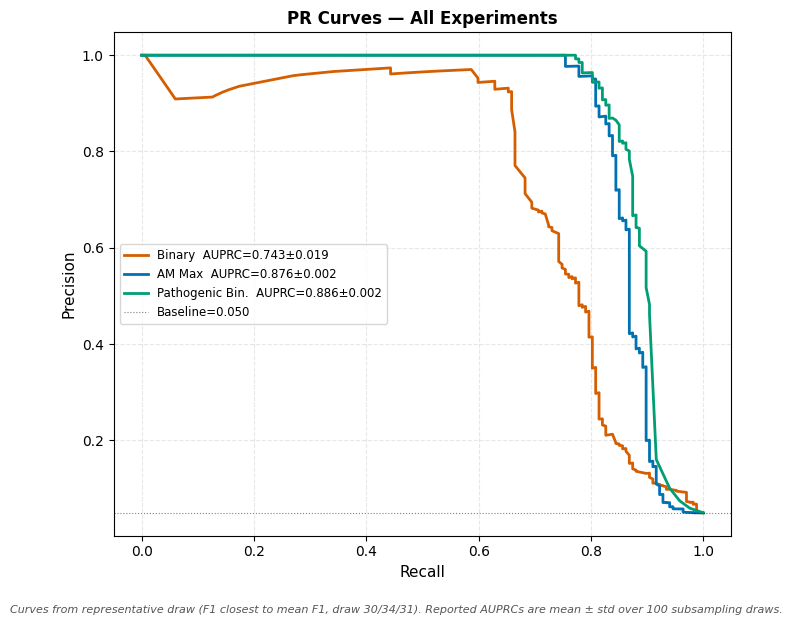

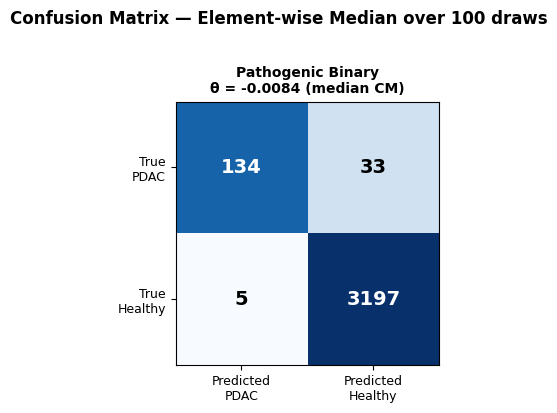

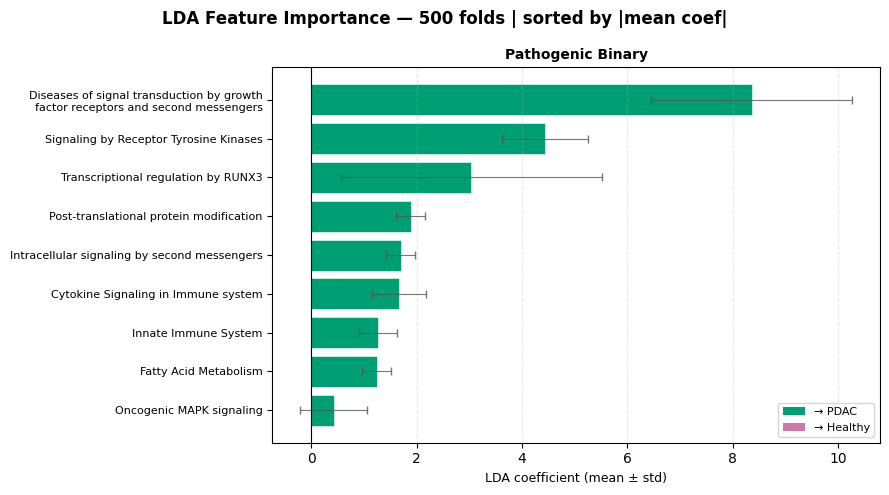

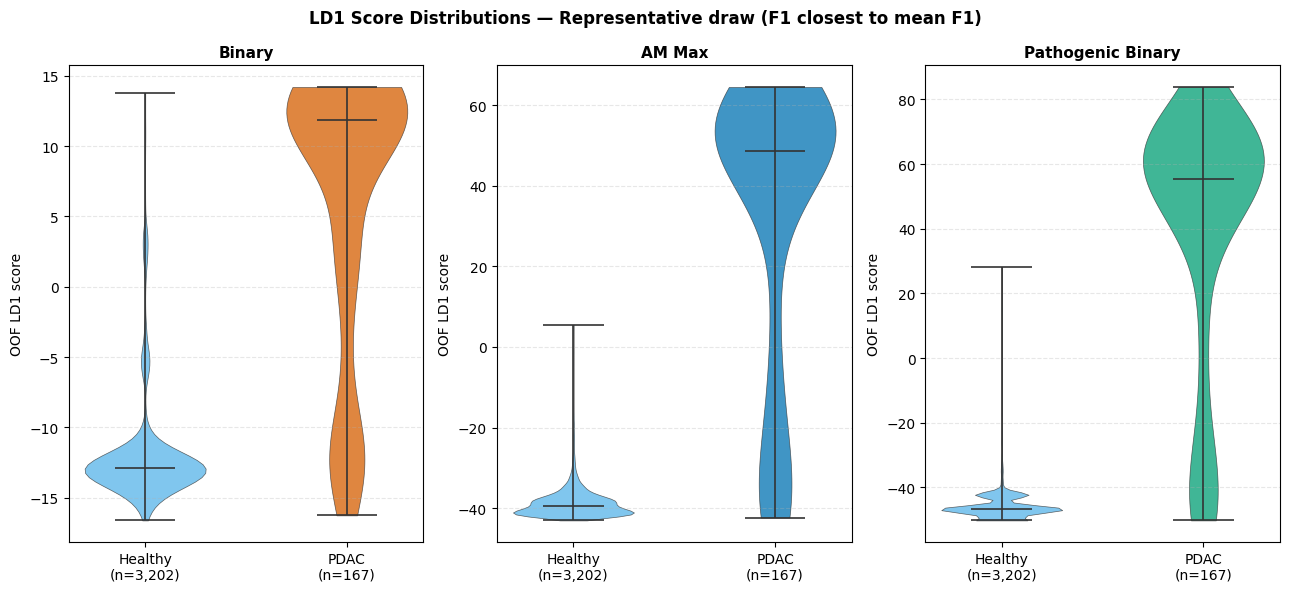

In [18]:
C1, C2, C3 = WONG['vermilion'], WONG['blue'], WONG['green']

# Representative draw per experiment (draw whose F1 is closest to mean F1)
rep_b_bin  = int(np.argmin(np.abs(_f1_arr_bin  - f1_bin)))
rep_b_am   = int(np.argmin(np.abs(_f1_arr_am   - f1_am)))
rep_b_path = int(np.argmin(np.abs(_f1_arr_path - f1_path)))

# ROC / PR curves from representative draws
fpr_bin,  tpr_bin,  _ = roc_curve(y, oof_scores_bin_arr[rep_b_bin])
fpr_am,   tpr_am,   _ = roc_curve(y, oof_scores_am_arr[rep_b_am])
fpr_path, tpr_path, _ = roc_curve(y, oof_scores_path_arr[rep_b_path])

prec_curve_bin,  rec_curve_bin,  _ = precision_recall_curve(y, oof_scores_bin_arr[rep_b_bin])
prec_curve_am,   rec_curve_am,   _ = precision_recall_curve(y, oof_scores_am_arr[rep_b_am])
prec_curve_path, rec_curve_path, _ = precision_recall_curve(y, oof_scores_path_arr[rep_b_path])

# Representative draw scores for violin plots
rep_scores_bin  = oof_scores_bin_arr[rep_b_bin]
rep_scores_am   = oof_scores_am_arr[rep_b_am]
rep_scores_path = oof_scores_path_arr[rep_b_path]

# Element-wise median CMs over 1000 draws (labels=[1,0] => PDAC row/col first)
cms_bin  = np.array([confusion_matrix(y, (oof_scores_bin_arr[b]  >= _thresh_arr_bin[b]).astype(int),  labels=[1, 0]) for b in range(N_DRAWS)])
cms_am   = np.array([confusion_matrix(y, (oof_scores_am_arr[b]   >= _thresh_arr_am[b]).astype(int),   labels=[1, 0]) for b in range(N_DRAWS)])
cms_path = np.array([confusion_matrix(y, (oof_scores_path_arr[b] >= _thresh_arr_path[b]).astype(int), labels=[1, 0]) for b in range(N_DRAWS)])

cm_med_bin  = np.median(cms_bin,  axis=0).astype(int)
cm_med_am   = np.median(cms_am,   axis=0).astype(int)
cm_med_path = np.median(cms_path, axis=0).astype(int)

# ── Metrics comparison table ──────────────────────────────────────────────────
display(pl.DataFrame({
    'Metric': [
        'AUROC (OOF)', 'AUPRC (OOF)',
        'AUROC (Apparent)', 'AUPRC (Apparent)',
        'Precision (F1-opt)', 'Recall (F1-opt)',
        'Specificity (F1-opt)', 'F1 (F1-opt)',
    ],
    'Binary': [
        f'{auroc_bin:.4f} ± {draw_auc_std_bin:.4f}',
        f'{auprc_bin:.4f} ± {draw_auprc_std_bin:.4f}',
        f'{auroc_apparent_bin:.4f} ± {auroc_apparent_std_bin:.4f}',
        f'{auprc_apparent_bin:.4f} ± {auprc_apparent_std_bin:.4f}',
        f'{precision_bin:.4f} ± {precision_std_bin:.4f}',
        f'{recall_bin:.4f} ± {recall_std_bin:.4f}',
        f'{specificity_bin:.4f} ± {specificity_std_bin:.4f}',
        f'{f1_bin:.4f} ± {f1_std_bin:.4f}',
    ],
    'AM Max': [
        f'{auroc_am:.4f} ± {draw_auc_std_am:.4f}',
        f'{auprc_am:.4f} ± {draw_auprc_std_am:.4f}',
        f'{auroc_apparent_am:.4f} ± {auroc_apparent_std_am:.4f}',
        f'{auprc_apparent_am:.4f} ± {auprc_apparent_std_am:.4f}',
        f'{precision_am:.4f} ± {precision_std_am:.4f}',
        f'{recall_am:.4f} ± {recall_std_am:.4f}',
        f'{specificity_am:.4f} ± {specificity_std_am:.4f}',
        f'{f1_am:.4f} ± {f1_std_am:.4f}',
    ],
    'Pathogenic Binary': [
        f'{auroc_path:.4f} ± {draw_auc_std_path:.4f}',
        f'{auprc_path:.4f} ± {draw_auprc_std_path:.4f}',
        f'{auroc_apparent_path:.4f} ± {auroc_apparent_std_path:.4f}',
        f'{auprc_apparent_path:.4f} ± {auprc_apparent_std_path:.4f}',
        f'{precision_path:.4f} ± {precision_std_path:.4f}',
        f'{recall_path:.4f} ± {recall_std_path:.4f}',
        f'{specificity_path:.4f} ± {specificity_std_path:.4f}',
        f'{f1_path:.4f} ± {f1_std_path:.4f}',
    ],
}))

# ── Figure 1: PR curve ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))
for label, color, rec_o, prec_o, auprc_o, auprc_std in [
    ('Binary',          C1, rec_curve_bin,  prec_curve_bin,  auprc_bin,  draw_auprc_std_bin),
    ('AM Max',          C2, rec_curve_am,   prec_curve_am,   auprc_am,   draw_auprc_std_am),
    ('Pathogenic Bin.', C3, rec_curve_path, prec_curve_path, auprc_path, draw_auprc_std_path),
]:
    ax.plot(rec_o, prec_o, color=color, lw=2,
            label=f'{label}  AUPRC={auprc_o:.3f}±{auprc_std:.3f}')
ax.axhline(pdac_prevalence, color='black', lw=0.8, ls=':', alpha=0.5,
           label=f'Baseline={pdac_prevalence:.3f}')
ax.set_xlabel('Recall', fontsize=11)
ax.set_ylabel('Precision', fontsize=11)
ax.set_title('PR Curves — All Experiments', fontsize=12, fontweight='bold')
ax.legend(fontsize=8.5); ax.grid(alpha=0.3, ls='--')
fig.text(0.5, -0.03,
         f'Curves from representative draw (F1 closest to mean F1, draw {rep_b_bin}/{rep_b_am}/{rep_b_path}). '
         f'Reported AUPRCs are mean ± std over {N_DRAWS} subsampling draws.',
         ha='center', fontsize=8, style='italic', color='#555555')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_comparison_roc_pr.png',
            dpi=150, bbox_inches='tight')
plt.savefig((RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_comparison_roc_pr.png').with_suffix('.svg'), bbox_inches='tight')
plt.show()

# ── Figure 2: Confusion matrix (element-wise median over N_DRAWS draws) ─────────────
fig, ax = plt.subplots(figsize=(4, 4))
display_labels = ['PDAC', 'Healthy']
cm_norm = cm_med_path.astype(float) / cm_med_path.sum(axis=1, keepdims=True)
ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        text_color = 'white' if cm_norm[i, j] > 0.55 else 'black'
        ax.text(j, i, str(cm_med_path[i, j]), ha='center', va='center',
                fontsize=14, fontweight='bold', color=text_color)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels([f'Predicted\n{display_labels[0]}', f'Predicted\n{display_labels[1]}'], fontsize=9)
ax.set_yticklabels([f'True\n{display_labels[0]}', f'True\n{display_labels[1]}'], fontsize=9)
ax.set_title(f'Pathogenic Binary\nθ = {threshold_path:.4f} (median CM)', fontsize=10, fontweight='bold')
plt.suptitle(f'Confusion Matrix — Element-wise Median over {N_DRAWS} draws',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_confusion_grid.png',
            dpi=150, bbox_inches='tight')
plt.savefig((RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_confusion_grid.png').with_suffix('.svg'), bbox_inches='tight')
plt.show()

# ── Figure 3: LDA coefficient bar charts ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
order = np.argsort(np.abs(mean_coef_path))
labels = [
    KOCOFX_HVP_PATHWAYS[i].replace('REACTOME_', '').replace('HALLMARK_', '').replace(
        'Diseases of signal transduction by growth factor receptors and second messengers',
        'Diseases of signal transduction by growth\nfactor receptors and second messengers')
    for i in order
]
vals = mean_coef_path[order]; errs = std_coef_path[order]
bar_colors = [C3 if v > 0 else WONG['sky_blue'] for v in vals]
ax.barh(range(len(vals)), vals, xerr=errs,
        error_kw={'ecolor': '#555555', 'capsize': 3, 'linewidth': 0.8, 'alpha': 0.8},
        color=bar_colors, edgecolor='white', linewidth=0.4)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('LDA coefficient (mean ± std)', fontsize=9)
ax.set_title('Pathogenic Binary', fontsize=10, fontweight='bold')
ax.legend(handles=[
    mpatches.Patch(facecolor=C3,           label='→ PDAC'),
    mpatches.Patch(facecolor=WONG['sky_blue'], label='→ Healthy'),
], fontsize=8)
ax.grid(axis='x', alpha=0.3, ls='--')
plt.suptitle(f'LDA Feature Importance — {N_DRAWS * N_CV_SPLITS:,} folds | sorted by |mean coef|',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_coef_grid.png',
            dpi=150, bbox_inches='tight')
plt.savefig((RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_coef_grid.png').with_suffix('.svg'), bbox_inches='tight')
plt.show()
# ── Figure 4: LD1 score violins (representative draw) ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(13, 6))
for ax, scores, color, exp_label in [
    (axes[0], rep_scores_bin,  C1, 'Binary'),
    (axes[1], rep_scores_am,   C2, 'AM Max'),
    (axes[2], rep_scores_path, C3, 'Pathogenic Binary'),
]:
    parts = ax.violinplot(
        [scores[y == 0], scores[y == 1]], positions=[0, 1],
        showmedians=True, showextrema=True, widths=0.6,
    )
    for pc, col in zip(parts['bodies'], [WONG['sky_blue'], color]):
        pc.set_facecolor(col); pc.set_alpha(0.75)
        pc.set_edgecolor('#333333'); pc.set_linewidth(0.5)
    for k in ('cbars', 'cmins', 'cmaxes', 'cmedians'):
        if k in parts:
            parts[k].set_color('#333333'); parts[k].set_linewidth(1.2)
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f'Healthy\n(n={N_HEALTHY:,})', f'PDAC\n(n={N_PDAC})'], fontsize=10)
    ax.set_ylabel('OOF LD1 score', fontsize=10)
    ax.set_title(exp_label, fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3, ls='--')
plt.suptitle(f'LD1 Score Distributions — Representative draw (F1 closest to mean F1)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_violin_grid.png',
            dpi=150, bbox_inches='tight')
plt.savefig((RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_violin_grid.png').with_suffix('.svg'), bbox_inches='tight')
plt.show()


Saved to C:\2604_BRP\Data\results\HvP_V2


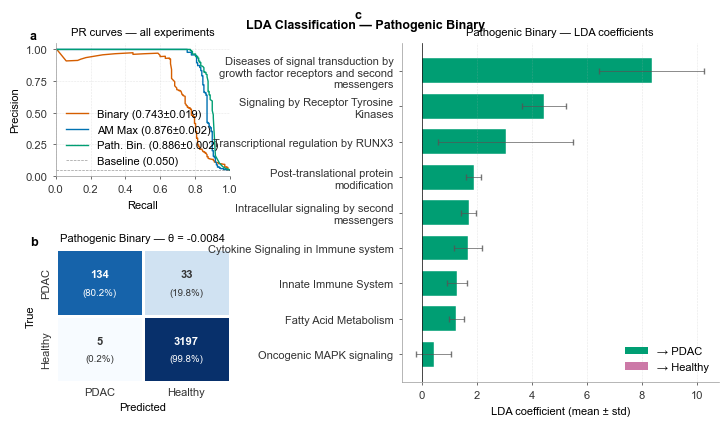

In [33]:
# ── 9b. Nature-style 3-panel figure: PR · CM · LDA coefficients ─────────────────
import matplotlib as mpl
from matplotlib import gridspec
import seaborn as sns
import textwrap

_mm = 1 / 25.4

with mpl.rc_context({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.linewidth': 0.5,
    'axes.edgecolor': '#999999',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 2.5,
    'ytick.major.size': 2.5,
    'svg.fonttype': 'none',
}):
    _fig9 = plt.figure(figsize=(183 * _mm, 105 * _mm))
    _gs9 = gridspec.GridSpec(
        2, 2, figure=_fig9,
        height_ratios=[1, 1],
        width_ratios=[0.55, 1.0],
        hspace=0.55, wspace=0.70,
        left=0.07, right=0.99, top=0.92, bottom=0.10,
    )
    _ax_pr = _fig9.add_subplot(_gs9[0, 0])   # top-left
    _ax_cm = _fig9.add_subplot(_gs9[1, 0])   # bottom-left
    _ax_bc = _fig9.add_subplot(_gs9[:, 1])    # right, full height

    # Bold panel labels
    for _ax9, _lbl9 in zip([_ax_pr, _ax_cm, _ax_bc], ['a', 'b', 'c']):
        _ax9.text(-0.15, 1.10, _lbl9, transform=_ax9.transAxes,
                  fontsize=9, fontweight='bold', va='top', ha='left')

    # ── a) PR curves \u2014 all three experiments ───────────────────────────────────
    for _label9, _color9, _rec9, _prec9, _auprc9, _std9 in [
        ('Binary',     C1, rec_curve_bin,  prec_curve_bin,  auprc_bin,  draw_auprc_std_bin),
        ('AM Max',     C2, rec_curve_am,   prec_curve_am,   auprc_am,   draw_auprc_std_am),
        ('Path. Bin.', C3, rec_curve_path, prec_curve_path, auprc_path, draw_auprc_std_path),
    ]:
        _ax_pr.plot(_rec9, _prec9, color=_color9, lw=1.0,
                    label=f'{_label9} ({_auprc9:.3f}\u00b1{_std9:.3f})')
    _ax_pr.axhline(pdac_prevalence, color='black', lw=0.5, ls='--', alpha=0.4,
                   label=f'Baseline ({pdac_prevalence:.3f})')
    _ax_pr.set_xlim(0, 1)
    _ax_pr.set_ylim(0, 1.05)
    _ax_pr.set_xlabel('Recall')
    _ax_pr.set_ylabel('Precision')
    _ax_pr.set_title('PR curves \u2014 all experiments')
    _ax_pr.legend(frameon=False, loc='lower left')
    _ax_pr.grid(alpha=0.3, ls='--', linewidth=0.4)
    sns.despine(ax=_ax_pr)

    # ── b) Confusion matrix \u2014 Pathogenic Binary (KO5 style) ─────────────────
    _cm_norm9 = cm_med_path.astype(float) / cm_med_path.sum(axis=1, keepdims=True)
    sns.heatmap(
        _cm_norm9, annot=False, cmap='Blues', vmin=0, vmax=1,
        xticklabels=['PDAC', 'Healthy'], yticklabels=['PDAC', 'Healthy'],
        linewidths=1.0, linecolor='white', ax=_ax_cm, cbar=False,
    )
    for _i9 in range(2):
        for _j9 in range(2):
            _tc9 = 'white' if _cm_norm9[_i9, _j9] > 0.55 else '#333333'
            _ax_cm.text(_j9 + 0.5, _i9 + 0.38, f'{cm_med_path[_i9, _j9]}',
                        ha='center', va='center', fontweight='bold', color=_tc9)
            _pct9 = _cm_norm9[_i9, _j9] * 100
            _ax_cm.text(_j9 + 0.5, _i9 + 0.65, f'({_pct9:.1f}%)',
                        ha='center', va='center', fontsize=7, color=_tc9)
    _ax_cm.set_xlabel('Predicted')
    _ax_cm.set_ylabel('True')
    _ax_cm.set_title(f'Pathogenic Binary \u2014 \u03b8 = {threshold_path:.4f}')
    _ax_cm.tick_params(axis='both', length=0)

    # ── c) LDA coefficient bar chart \u2014 Pathogenic Binary ─────────────────────
    _order9 = np.argsort(np.abs(mean_coef_path))
    _labels9 = [
        KOCOFX_HVP_PATHWAYS[i].replace('REACTOME_', '').replace('HALLMARK_', '')
        for i in _order9
    ]
    _labels9 = [textwrap.fill(l, 35) for l in _labels9]
    _vals9 = mean_coef_path[_order9]
    _errs9 = std_coef_path[_order9]
    _bar_colors9 = [C3 if v > 0 else WONG['sky_blue'] for v in _vals9]
    _ax_bc.barh(range(len(_vals9)), _vals9, xerr=_errs9,
                error_kw={'ecolor': '#555555', 'capsize': 2, 'linewidth': 0.6, 'alpha': 0.8},
                color=_bar_colors9, edgecolor='white', linewidth=0.3, height=0.7)
    _ax_bc.set_yticks(range(len(_labels9)))
    _ax_bc.set_yticklabels(_labels9)
    _ax_bc.axvline(0, color='black', linewidth=0.5)
    _ax_bc.set_xlabel('LDA coefficient (mean \u00b1 std)')
    _ax_bc.set_title('Pathogenic Binary \u2014 LDA coefficients')
    _ax_bc.legend(handles=[
        mpatches.Patch(facecolor=C3,           label='\u2192 PDAC'),
        mpatches.Patch(facecolor=WONG['sky_blue'], label='\u2192 Healthy'),
    ], frameon=False, loc='lower right')
    _ax_bc.grid(axis='x', alpha=0.3, ls='--', linewidth=0.4)
    sns.despine(ax=_ax_bc)

    _fig9.suptitle(
        'LDA Classification \u2014 Pathogenic Binary',
        fontsize=9, fontweight='bold',
    )

    _figname9 = 'LDA_KoCoFX_HvP_V2_nature_panel'
    plt.savefig(RESULTS_DIR / f'{_figname9}.pdf', dpi=300)
    plt.savefig(RESULTS_DIR / f'{_figname9}.png', dpi=300)
    with mpl.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(RESULTS_DIR / f'{_figname9}.svg')
    print('Saved to', RESULTS_DIR.resolve())
    plt.show()


## 10. Results File

In [19]:
_comp_rows = [
    ('AUROC (OOF)',
     f'{auroc_bin:.4f} ± {draw_auc_std_bin:.4f}',
     f'{auroc_am:.4f} ± {draw_auc_std_am:.4f}',
     f'{auroc_path:.4f} ± {draw_auc_std_path:.4f}'),
    ('AUPRC (OOF)',
     f'{auprc_bin:.4f} ± {draw_auprc_std_bin:.4f}',
     f'{auprc_am:.4f} ± {draw_auprc_std_am:.4f}',
     f'{auprc_path:.4f} ± {draw_auprc_std_path:.4f}'),
    ('AUROC (Apparent)',
     f'{auroc_apparent_bin:.4f} ± {auroc_apparent_std_bin:.4f}',
     f'{auroc_apparent_am:.4f} ± {auroc_apparent_std_am:.4f}',
     f'{auroc_apparent_path:.4f} ± {auroc_apparent_std_path:.4f}'),
    ('AUPRC (Apparent)',
     f'{auprc_apparent_bin:.4f} ± {auprc_apparent_std_bin:.4f}',
     f'{auprc_apparent_am:.4f} ± {auprc_apparent_std_am:.4f}',
     f'{auprc_apparent_path:.4f} ± {auprc_apparent_std_path:.4f}'),
    ('Precision (F1-opt)',
     f'{precision_bin:.4f} ± {precision_std_bin:.4f}',
     f'{precision_am:.4f} ± {precision_std_am:.4f}',
     f'{precision_path:.4f} ± {precision_std_path:.4f}'),
    ('Recall (F1-opt)',
     f'{recall_bin:.4f} ± {recall_std_bin:.4f}',
     f'{recall_am:.4f} ± {recall_std_am:.4f}',
     f'{recall_path:.4f} ± {recall_std_path:.4f}'),
    ('Specificity (F1-opt)',
     f'{specificity_bin:.4f} ± {specificity_std_bin:.4f}',
     f'{specificity_am:.4f} ± {specificity_std_am:.4f}',
     f'{specificity_path:.4f} ± {specificity_std_path:.4f}'),
    ('F1 (F1-opt)',
     f'{f1_bin:.4f} ± {f1_std_bin:.4f}',
     f'{f1_am:.4f} ± {f1_std_am:.4f}',
     f'{f1_path:.4f} ± {f1_std_path:.4f}'),
]
lines = []
lines.append('=' * 80)
lines.append('KO6 -- Subagging-Ensemble LDA: Healthy vs PDAC')
lines.append('=' * 80)
lines.append('')
lines.append('SETUP')
lines.append(f'  Classifier    : LDA (eigen solver, Ledoit-Wolf shrinkage)')
lines.append(f'  Features      : 9 KoCoFX-HvP pathways')
lines.append(f'  Draws         : {N_DRAWS}')
lines.append(f'  CV splits     : {N_CV_SPLITS}-fold stratified (seed={RANDOM_SEED})')
lines.append(f'  Total fits    : {N_DRAWS * N_CV_SPLITS:,} per experiment')
lines.append(f'  PDAC          : {N_PDAC} patients (TCGA-PAAD, TMB <= 500)')
lines.append(f'  Healthy       : {N_HEALTHY:,} individuals (1000G, all per draw)')
lines.append(f'  Total n       : {n_total}')
lines.append(f'  Aggregation   : mean +/- std over {N_DRAWS} draws (Method B: per-draw metric, then average)')
lines.append('')

for exp_name, auroc, auprc, auroc_ap, auroc_ap_std, auprc_ap, auprc_ap_std, prec, prec_std, rec, rec_std, spec, spec_std, f1, f1_std, auc_std, auprc_oof_std, thr, mc, sc in [
    ('Experiment 1 -- Binary',
     auroc_bin, auprc_bin,
     auroc_apparent_bin, auroc_apparent_std_bin, auprc_apparent_bin, auprc_apparent_std_bin,
     precision_bin, precision_std_bin, recall_bin, recall_std_bin,
     specificity_bin, specificity_std_bin, f1_bin, f1_std_bin,
     draw_auc_std_bin, draw_auprc_std_bin, threshold_bin, mean_coef_bin, std_coef_bin),
    ('Experiment 2 -- AM Max',
     auroc_am, auprc_am,
     auroc_apparent_am, auroc_apparent_std_am, auprc_apparent_am, auprc_apparent_std_am,
     precision_am, precision_std_am, recall_am, recall_std_am,
     specificity_am, specificity_std_am, f1_am, f1_std_am,
     draw_auc_std_am, draw_auprc_std_am, threshold_am, mean_coef_am, std_coef_am),
    ('Experiment 3 -- Pathogenic Binary',
     auroc_path, auprc_path,
     auroc_apparent_path, auroc_apparent_std_path, auprc_apparent_path, auprc_apparent_std_path,
     precision_path, precision_std_path, recall_path, recall_std_path,
     specificity_path, specificity_std_path, f1_path, f1_std_path,
     draw_auc_std_path, draw_auprc_std_path, threshold_path, mean_coef_path, std_coef_path),
]:
    lines.append('=' * 80)
    lines.append(exp_name)
    lines.append('=' * 80)
    lines.append(f'  AUROC (OOF)          : {auroc:.4f} +/- {auc_std:.4f}')
    lines.append(f'  AUPRC (OOF)          : {auprc:.4f} +/- {auprc_oof_std:.4f}')
    lines.append(f'  AUROC (Apparent)     : {auroc_ap:.4f} +/- {auroc_ap_std:.4f}')
    lines.append(f'  AUPRC (Apparent)     : {auprc_ap:.4f} +/- {auprc_ap_std:.4f}')
    lines.append(f'  Precision (F1-opt)   : {prec:.4f} +/- {prec_std:.4f}')
    lines.append(f'  Recall    (F1-opt)   : {rec:.4f} +/- {rec_std:.4f}')
    lines.append(f'  Specificity (F1-opt) : {spec:.4f} +/- {spec_std:.4f}')
    lines.append(f'  F1        (F1-opt)   : {f1:.4f} +/- {f1_std:.4f}')
    lines.append(f'  F1-optimal threshold : {thr:.4f} (mean over draws)')
    lines.append('')
    lines.append('  LDA COEFFICIENTS (ranked by |mean|):')
    lines.append(f'  {"Rank":<5}  {"Pathway":<75}  {"Mean":>8}  {"Std":>7}  Direction')
    lines.append('  ' + '-' * 108)
    for rank, i in enumerate(np.argsort(np.abs(mc))[::-1], 1):
        pw    = KOCOFX_HVP_PATHWAYS[i]
        direc = '-> PDAC' if mc[i] > 0 else '-> Healthy'
        lines.append(f'  {rank:<5}  {pw:<75}  {mc[i]:>+8.4f}  {sc[i]:>7.4f}  {direc}')
    lines.append('')

lines.append('=' * 80)
lines.append('COMPARISON')
lines.append('=' * 80)
lines.append(f'  {"Metric":<28}  {"Binary":>18}  {"AM Max":>18}  {"Pathogenic":>18}')
lines.append('  ' + '-' * 90)
for label, v1, v2, v3 in _comp_rows:
    lines.append(f'  {label:<28}  {v1:>18}  {v2:>18}  {v3:>18}')

out_txt = RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_results.txt'
out_txt.write_text('\n'.join(lines), encoding='utf-8')
print(f'Results written -> {out_txt}')


Results written -> C:\Users\daane\Desktop\DATA\results\HvP_V2\LDA_KoCoFX_HvP_V2_results.txt


## 11. Export Representative-Draw Scores

Persist the chosen representative draw's per-sample discriminant scores (selected by F1 closest to mean F1, see Section 9) to a tidy `sample_id`-keyed parquet file, so downstream notebooks (e.g. `KO6_Scatter_Plot.ipynb`) can reuse these honest, out-of-fold scores without re-deriving the bootstrap/CV pipeline or its draw-selection logic.

In [20]:
healthy_ids = sorted(
    df_bootstrap.filter(pl.col('bootstrap_id') == rep_b_path)['sample_id'].unique().to_list()
)  # verified: identical set across all 1000 draws (bootstrap resamples mutation profiles,
   # not which individuals are included), so this single id list correctly maps rows for
   # bin/am/path alike, regardless of which draw index each representation's own selection picked.

df_export = pl.DataFrame({
    'sample_id': healthy_ids + pdac_ids,
    'group': ['Healthy'] * len(healthy_ids) + ['PDAC'] * len(pdac_ids),
    'rep_score_bin':  rep_scores_bin,
    'rep_score_am':   rep_scores_am,
    'rep_score_path': rep_scores_path,
})
assert df_export.shape[0] == n_total
assert df_export['rep_score_path'].null_count() == 0

export_path = RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_representative_scores.parquet'
df_export.write_parquet(export_path)

# Sidecar: persist which draw each representation selected, so downstream notebooks
# (e.g. KO6_Scatter_Plot.ipynb) can rebuild the SAME bootstrap draw's healthy mutation
# profiles for any other feature representation, instead of mixing this draw's HvP scores
# with a differently-sourced (e.g. raw, un-bootstrapped) healthy dataset on another axis.
draw_info_path = RESULTS_DIR / 'LDA_KoCoFX_HvP_V2_representative_draw.json'
draw_info_path.write_text(
    json.dumps({'rep_b_bin': rep_b_bin, 'rep_b_am': rep_b_am, 'rep_b_path': rep_b_path}),
    encoding='utf-8',
)

print(f'Representative-draw scores written -> {export_path}')
print(f'Representative-draw indices written -> {draw_info_path}')
print(f'  shape: {df_export.shape}')
print(f'  rep_b_bin={rep_b_bin}  rep_b_am={rep_b_am}  rep_b_path={rep_b_path}')


Representative-draw scores written -> C:\Users\daane\Desktop\DATA\results\HvP_V2\LDA_KoCoFX_HvP_V2_representative_scores.parquet
Representative-draw indices written -> C:\Users\daane\Desktop\DATA\results\HvP_V2\LDA_KoCoFX_HvP_V2_representative_draw.json
  shape: (3369, 5)
  rep_b_bin=30  rep_b_am=34  rep_b_path=31
